Regression Setup, Train-Test Split LAB

Membangun model Linear Regression untuk memprediksi median nilai rumah di California (`MedHouseVal`).

Dataset: `california_housing.csv` 

Dataset California Housing berisi informasi demografis dan karakteristik wilayah perumahan di California. Target yang akan diprediksi adalah `MedHouseVal`.

Import Library

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler, MaxAbsScaler

Soal 1

Import data menggunakan Pandas dan periksa:
- Ukuran dataset (jumlah baris dan kolom).
- Lima baris pertama.
- Nama kolom.
- Tipe data setiap kolom.
- Statistik deskriptif.

Pastikan file `california_housing.csv` berada di folder `data/`.

In [2]:
data = pd.read_csv("data/california_housing.csv")

print("Shape:", data.shape)
display(data.head())
print("\\nColumns:", data.columns.tolist())
print("\\nData types:")
display(data.dtypes.value_counts())
display(data.describe())

Shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


\nColumns: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']
\nData types:


float64    9
Name: count, dtype: int64

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


Berapa jumlah baris dan kolom? Apakah ada kolom bertipe kategorikal? Kolom mana yang akan menjadi target prediksi?

In [3]:
#Periksa nilai kosong dan tipe data
display(data.isnull().sum())
display(data.dtypes)

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object

Soal 2

Untuk California Housing, semua fitur merupakan numerik. Periksa kolom bertipe `object` dan jumlah nilai uniknya. Jika tidak ada kolom kategorikal, jelaskan mengapa One-Hot Encoding tidak diperlukan.

In [4]:
categorical_cols = data.select_dtypes(include=["object", "category"]).columns

print("Kolom kategorikal:", list(categorical_cols))
print("Jumlah kolom kategorikal:", len(categorical_cols))

if len(categorical_cols) > 0:
    display(data[categorical_cols].nunique(dropna=False))
else:
    print("Tidak ada kolom kategorikal; One-Hot Encoding tidak diperlukan.")

Kolom kategorikal: []
Jumlah kolom kategorikal: 0
Tidak ada kolom kategorikal; One-Hot Encoding tidak diperlukan.


Soal 3

Siapkan data untuk pemodelan:
- Buat salinan dataset.
- Pisahkan target `MedHouseVal` dari fitur.
- Periksa ukuran X dan y.

Pada latihan ini tidak dibuat dataset One-Hot Encoded karena seluruh fitur sudah numerik.

In [5]:
data_model = data.copy()

y_col = "MedHouseVal"
X_data = data_model.drop(columns=[y_col])
y_data = data_model[y_col]

print("Ukuran X:", X_data.shape)
print("Ukuran y:", y_data.shape)
print("Fitur:", X_data.columns.tolist())

Ukuran X: (20640, 8)
Ukuran y: (20640,)
Fitur: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


Soal 4

Buat train-test split dengan proporsi 70% data training dan 30% data testing. Gunakan `random_state=42` agar hasil pembagian dapat direproduksi.

Kemudian latih model Linear Regression pada data training dan hitung MSE serta R² pada data training dan testing.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X_data, y_data, test_size=0.30, random_state=42
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (14448, 8)
X_test : (6192, 8)
y_train: (14448,)
y_test : (6192,)


In [7]:
LR = LinearRegression()
LR.fit(X_train, y_train)

y_train_pred = LR.predict(X_train)
y_test_pred = LR.predict(X_test)

baseline_results = pd.DataFrame({
    "Dataset": ["Original - Train", "Original - Test"],
    "MSE": [
        mean_squared_error(y_train, y_train_pred),
        mean_squared_error(y_test, y_test_pred)
    ],
    "R2": [
        r2_score(y_train, y_train_pred),
        r2_score(y_test, y_test_pred)
    ]
})

baseline_results

,Dataset,MSE,R2
0,Original - Train,0.523358,0.609346
1,Original - Test,0.530568,0.595770


Apakah MSE pada data training dan testing sama? Apa arti perbedaan nilai tersebut? Bandingkan juga nilai R² keduanya.

Question 5

Bandingkan performa model setelah melakukan scaling pada fitur menggunakan:
- `StandardScaler`
- `MinMaxScaler`
- `MaxAbsScaler`

Penting: scaler hanya di-fit menggunakan data training, lalu digunakan untuk mentransformasi data training dan testing. Cara ini mencegah data leakage.

In [8]:
scalers = {
    "standard": StandardScaler(),
    "minmax": MinMaxScaler(),
    "maxabs": MaxAbsScaler()
}

scaling_results = []

for scaler_name, scaler in scalers.items():
    # Fit scaler hanya pada data training
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    model = LinearRegression()
    model.fit(X_train_scaled, y_train)

    train_pred = model.predict(X_train_scaled)
    test_pred = model.predict(X_test_scaled)

    scaling_results.append({
        "Scaler": scaler_name,
        "Train MSE": mean_squared_error(y_train, train_pred),
        "Test MSE": mean_squared_error(y_test, test_pred),
        "Train R2": r2_score(y_train, train_pred),
        "Test R2": r2_score(y_test, test_pred)
    })

scaling_results = pd.DataFrame(scaling_results)
scaling_results

,Scaler,Train MSE,Test MSE,Train R2,Test R2
0,standard,0.523358,0.530568,0.609346,0.59577
1,minmax,0.523358,0.530568,0.609346,0.59577
2,maxabs,0.523358,0.530568,0.609346,0.59577


Bandingkan hasil ketiga scaler dengan model original. Apakah scaling mengubah performa Linear Regression secara signifikan? Jelaskan berdasarkan MSE dan R² yang diperoleh.

Soal 6

Plot nilai prediksi dibandingkan nilai aktual untuk salah satu model. Garis diagonal menunjukkan prediksi ideal: semakin dekat titik ke garis, semakin dekat prediksi dengan nilai aktual.

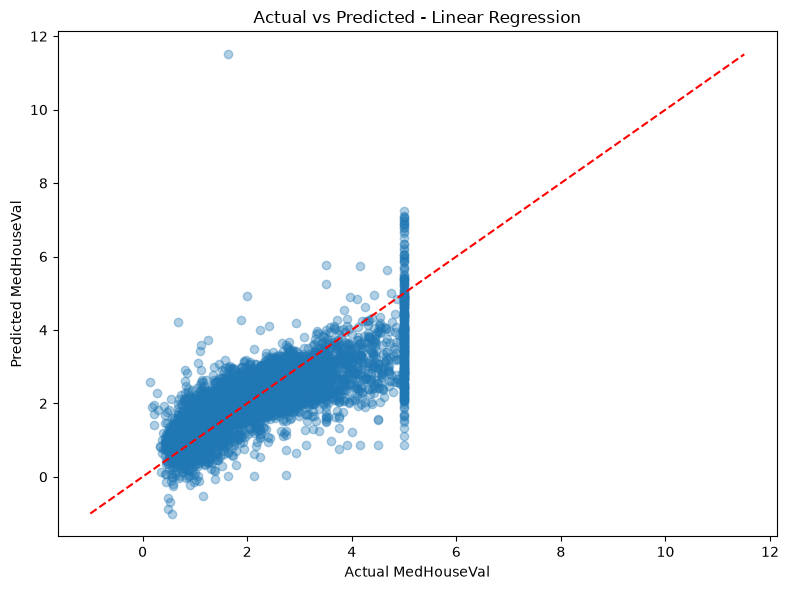

In [9]:
# Gunakan prediksi dari model baseline (fitur original)
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_test_pred, alpha=0.35)
min_value = min(y_test.min(), y_test_pred.min())
max_value = max(y_test.max(), y_test_pred.max())
plt.plot([min_value, max_value], [min_value, max_value], "r--")
plt.xlabel("Actual MedHouseVal")
plt.ylabel("Predicted MedHouseVal")
plt.title("Actual vs Predicted - Linear Regression")
plt.tight_layout()
plt.show()

Sumber Dataset

Mendeley Data - California Housing Dataset

Simpan file sebagai `data/california_housing.csv` sebelum menjalankan notebook.